# Quantitative comparison of focal-series (inline holography) reconstruction algorithms

This notebook simulates a **high-resolution (HR)** and a **medium-resolution (MR)** focal series,
reconstructs the exit wave with all algorithms implemented in `inlineholo`, and compares the
results with the ground truth by **Fourier ring correlation (FRC)** – as a function of electron dose.

* HR test object: SrTiO$_3$-like [001] crystal wedge (rounded particle with an O-vacancy column and a
  displaced Sr column) on amorphous carbon; 300 kV, aberration-corrected
  ($C_3 = 10\,\mu$m, residual $A_1$, $B_2$), 16 images, $C_1 = -16 \ldots +14$ nm,
  focal spread 2.5 nm, illumination convergence 0.1 mrad (rms).
* MR test object: MgO-like cube, carbon sphere with metal core, small particles on a thin amorphous
  film; phases from the mean inner potential (up to ~10 rad, i.e. strongly *wrapped*), 13 images with
  non-linearly spaced defoci between $\pm 8\,\mu$m.
* Images are simulated with the rigorous incoherent model (Gauss–Hermite quadrature with 9 defocus
  and 5×5 tilt nodes), a sinc detector MTF and Poisson noise. The reconstructions use *fewer* quadrature
  nodes or approximate coherence models, i.e. we avoid the "inverse crime".
* All focal series and reconstructions are stored in **NXem** (NeXus) files.

It further covers off-axis and hybrid holography (medium resolution), a learned method (MCNN) and strain mapping by
dark-field inline holography (DIH).

Method labels: **FRWR** = in-memory/GPU port of the FRWR3 C++ program (`inlineholo.frwr3`, validated against the
C++ code in Section 6b), **FRWR+GF** = FRWR3 with gradient flipping and incoherent background, **GP-FRWR** =
FRWR3 with gradient flipping, TIE phase prediction and incoherent background; **Flux-LSQ (GD)** and **GP-LSQ (GD)**
are our steepest-descent least-squares variants with the same flux-preserving image model (the latter with gradient
flipping and least-squares weighted phase prediction); **TIE (FP)** is the Fokker–Planck-consistent three-plane TIE.

Runtime: ≈ 80–100 min on 2 CPU cores, including ≈10 min MCNN training (set `FAST = True` for a ≈10 min version).

In [1]:
import os, sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath(os.path.join("..")))
import inlineholo as ih
from inlineholo import simulate as sim
from inlineholo.frc import align_global_phase, compare_to_truth, frc, binomial_split, half_bit_threshold
from inlineholo.optics import FourierGrid

FAST = False
FIG = os.path.abspath(os.path.join("..", "..", "manuscript", "figures") if os.path.isdir(os.path.join("..", "..", "manuscript")) else os.path.join("..", "results", "figures"))
DATA = os.path.abspath(os.path.join("..", "data"))
os.makedirs(FIG, exist_ok=True); os.makedirs(DATA, exist_ok=True)
plt.rcParams.update({"font.size": 8, "axes.titlesize": 8, "figure.dpi": 110,
                     "savefig.dpi": 300, "image.interpolation": "nearest"})
print("inlineholo", ih.__version__)

inlineholo 0.2.0


## 1  Test objects and imaging parameters

In [2]:
N = 256
p_hr = sim.hr_parameters(mtf={"type": "sinc"})
p_mr = sim.mr_parameters(mtf={"type": "sinc"})
gt_hr = sim.hr_object(N, p_hr.pixel_size_nm)
gt_mr = sim.mr_object(N, p_mr.pixel_size_nm, voltage_V=p_mr.voltage_V)
print("HR\n" + p_hr.summary(), "\n\nMR\n" + p_mr.summary())
print(f"\nHR phase range {np.angle(gt_hr).min():.2f}..{np.angle(gt_hr).max():.2f} rad")
print(f"MR (unwrapped) phase range up to {(np.log(gt_mr).imag).max():.2f} rad (wrapped in the wave)")

HR
U = 300.0 kV (lambda = 1.969 pm)
pixel = 0.04 nm, N_images = 16
defoci [nm] = [-16. -14. -12. -10.  -8.  -6.  -4.  -2.   0.   2.   4.   6.   8.  10.
  12.  14.]
focal spread = 2.5 nm, convergence (rms) = 0.1 mrad
aberrations [nm]: c_3_0=1e+04, c_1_2_a=1, c_1_2_b=0.6, c_2_1_a=40 

MR
U = 300.0 kV (lambda = 1.969 pm)
pixel = 1 nm, N_images = 13
defoci [nm] = [-8000. -4000. -2000. -1000.  -500.  -250.     0.   250.   500.  1000.
  2000.  4000.  8000.]
focal spread = 5 nm, convergence (rms) = 0.05 mrad
aberrations [nm]: c_3_0=1.2e+06

HR phase range -0.00..0.57 rad
MR (unwrapped) phase range up to 3.14 rad (wrapped in the wave)


In [3]:
def simulate_cached(name, gt, p):
    fn = os.path.join(DATA, f"{name}_noisefree.npy")
    if os.path.exists(fn):
        return np.load(fn)
    t = time.time()
    I0, _ = sim.simulate_focal_series(gt, p, dose_per_image=None, n_defocus=9, n_tilt=5)
    np.save(fn, I0); print(f"{name}: simulated in {time.time()-t:.0f} s")
    return I0

I0_hr = simulate_cached("hr", gt_hr, p_hr)
I0_mr = simulate_cached("mr", gt_mr, p_mr)

### Transfer of the focal series

For linear imaging, the information about the scattered wave at spatial frequency $q$ that is
contained in the whole series is governed by $\sum_n |T_n(q)|^2$ (wave) and the ability to separate
it from its twin, $\left|\sum_n T_n(q)T_n(-q)\right|$ (Schiske). The low frequencies are transferred
poorly by both series – this is the generic weakness of inline holography.

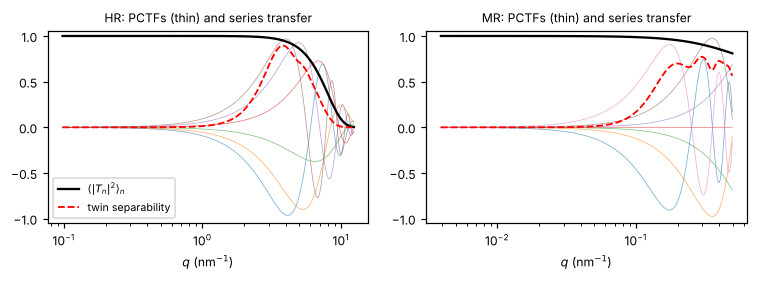

In [4]:
def series_transfer(p, shape):
    fm = ih.ForwardModel(p, shape, "envelope", use_mtf=False)
    T = np.stack([n[0][0] for n in fm.nodes])
    Tm = np.stack([np.roll(t[::-1, ::-1], 1, axis=(0, 1)) for t in T])
    # determinant of the 2x2 Schiske normal matrix / N^2 : 1 = perfect separation of wave and twin
    a11 = np.mean(np.abs(T)**2, 0); a22 = np.mean(np.abs(Tm)**2, 0); a12 = np.mean(np.conj(T)*np.conj(Tm), 0)
    det = (a11*a22 - np.abs(a12)**2)
    g = FourierGrid(shape, p.pixel_size_nm)
    q = g.q[0, : shape[1]//2]
    return q, a11[0, : shape[1]//2], det[0, : shape[1]//2], np.stack([np.sin(np.angle(np.conj(t))) * np.abs(t) for t in T])[:, 0, : shape[1]//2]

fig, ax = plt.subplots(1, 2, figsize=(7, 2.6))
for a, p, name in ((ax[0], p_hr, "HR"), (ax[1], p_mr, "MR")):
    q, s, det, pctf = series_transfer(p, (N, N))
    for k in range(0, p.n_images, max(1, p.n_images // 5)):
        a.plot(q[1:], pctf[k, 1:], lw=0.5, alpha=0.6)
    a.plot(q[1:], s[1:], "k", lw=1.5, label=r"$\langle|T_n|^2\rangle_n$")
    a.plot(q[1:], det[1:], "r--", lw=1.2, label="twin separability")
    a.set_xscale("log"); a.set_xlabel(r"$q$ (nm$^{-1}$)"); a.set_title(f"{name}: PCTFs (thin) and series transfer")
    a.set_ylim(-1.05, 1.05)
ax[0].legend(loc="lower left", fontsize=7)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "fig_transfer.pdf")); plt.show()

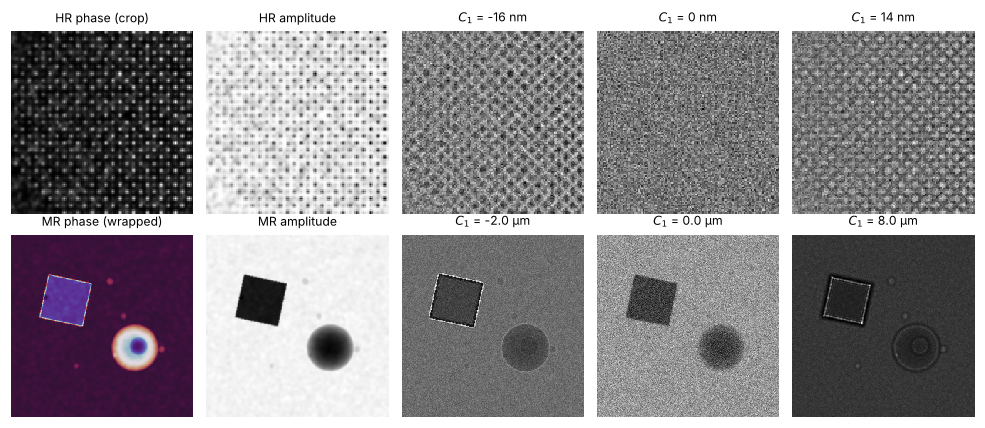

In [5]:
dose_ref = {"hr": 2e4, "mr": 20.0}           # total dose of the whole series in e/A^2
rng = np.random.default_rng(42)
def noisy(I0, p, total_dose, seed=0):
    d = sim.dose_per_pixel(total_dose, p.pixel_size_nm, p.n_images)
    return np.random.default_rng(seed).poisson(np.maximum(I0, 0) * d).astype(float)

I_hr = noisy(I0_hr, p_hr, dose_ref["hr"]); I_mr = noisy(I0_mr, p_mr, dose_ref["mr"])

fig, ax = plt.subplots(2, 5, figsize=(9, 3.9))
c = slice(64, 192)
ax[0, 0].imshow(np.angle(gt_hr)[c, c], cmap="gray"); ax[0, 0].set_title("HR phase (crop)")
ax[0, 1].imshow(np.abs(gt_hr)[c, c], cmap="gray"); ax[0, 1].set_title("HR amplitude")
for k, i in enumerate((0, 8, 15)):
    ax[0, 2 + k].imshow(I_hr[i][c, c], cmap="gray"); ax[0, 2 + k].set_title(f"$C_1$ = {p_hr.defoci_nm[i]:.0f} nm")
ax[1, 0].imshow(np.angle(gt_mr), cmap="twilight"); ax[1, 0].set_title("MR phase (wrapped)")
ax[1, 1].imshow(np.abs(gt_mr), cmap="gray"); ax[1, 1].set_title("MR amplitude")
for k, i in enumerate((2, 6, 12)):
    ax[1, 2 + k].imshow(I_mr[i], cmap="gray"); ax[1, 2 + k].set_title(f"$C_1$ = {p_mr.defoci_nm[i]/1e3:.1f} µm")
for a in ax.ravel(): a.axis("off")
fig.tight_layout(); fig.savefig(os.path.join(FIG, "fig_testobjects.pdf")); plt.show()

## 2  Reconstruction methods

The registry `ih.list_methods()` lists every algorithm with its category (direct/linear, projection,
optimization), whether it is linear in the data, how partial coherence is treated and which noise model
is implied.

In [6]:
pd.set_option("display.max_colwidth", 80)
pd.DataFrame(ih.list_methods()).T[["category", "linear", "coherence", "noise", "description"]]

,category,linear,coherence,noise,description
tie,direct-linear,True,none,none (Tikhonov),"TIE, uniform intensity, nearest planes"
tie_full,direct-linear,True,none,none (Tikhonov),TIE with non-uniform intensity (Teague auxiliary function)
tie_poly,direct-linear,True,none,LSQ fit,higher-order TIE: polynomial fit through all planes
tie_fp,direct-linear,True,Fokker-Planck: dz^2 diffusion terms eliminated,none (Tikhonov),"Fokker-Planck-consistent TIE (3 nearest planes, quadratic fit) + diffusion f..."
mftie,direct-linear,True,spatial envelope per defocus pair (flux-preserving blur),HNDS band filters,multi-focus TIE with overlapping filters (Eljarrat et al. 2018)
gftie,direct-linear + sparsity,False,none,gradient-sparsity prior,gradient-flipping TIE (Parvizi et al. 2016)
pam,direct-linear,True,envelope (exact for linear terms),Wiener,parabola method / linear focal-series restoration
schiske,direct-linear,True,envelope (exact for linear terms),Wiener,Schiske linear least-squares filter with twin separation
gs,projection,False,none (coherent),amplitude LSQ (implicit),sequential Gerchberg-Saxton/Misell
iwfr,projection,False,none (coherent),amplitude LSQ (implicit),IWFR (Allen et al.)


### Learned reconstruction: training the MCNN (medium resolution)

The multi-resolution CNN of Wang *et al.* (2020) is trained on focal series simulated with the fast
flux-preserving forward model from *random* medium-resolution objects (cubes, spheres with cores, small
particles, amorphous film; `simulate.random_mr_object`) with random doses between 1 and 300 e/Å$^2$.
The test object itself is not part of the training set, but it is drawn from a similar distribution –
which favours the learned method. Training (~10 min on 2 CPU cores) is done once and cached.

In [7]:
from inlineholo import offaxis, strain
try:
    import torch
    from inlineholo import mcnn
    torch.set_num_threads(os.cpu_count() or 2)
    HAVE_TORCH = True
except ImportError:
    HAVE_TORCH = False
MCNN_PATH = os.path.join(DATA, "mcnn_mr.pt")
mcnn_model = None
if HAVE_TORCH:
    if os.path.exists(MCNN_PATH):
        mcnn_model, _ = mcnn.load(MCNN_PATH)
    else:
        t0 = time.time()
        Xtr, Ytr = mcnn.make_training_set(p_mr, n_samples=2048, n=128, dose_range=(1, 300), seed=11)
        mcnn_model, mcnn_hist = mcnn.train(p_mr, Xtr, Ytr, width=16, depth=4,
                                           time_budget_s=120 if FAST else 600, verbose=False)
        mcnn.save(mcnn_model, MCNN_PATH, meta=dict(params=p_mr.to_dict(), samples=2048))
        del Xtr, Ytr
        print(f"MCNN trained in {time.time() - t0:.0f} s, final loss {np.mean(mcnn_hist[-50:]):.3f}")
print("MCNN available:", mcnn_model is not None)

MCNN available: True


In [8]:
it = dict(proj=40 if FAST else 60, grad=60 if FAST else 100, lbfgs=50 if FAST else 80, ml=30 if FAST else 60)
CONFIG = {
  "hr": [
    ("TIE",            "tie",        {}),
    ("TIE (poly)",     "tie_poly",   {}),
    ("TIE (FP)",       "tie_fp",     {}),
    ("MFTIE",          "mftie",      {}),
    ("GF-TIE",         "gftie",      dict(n_iter=30)),
    ("PAM",            "pam",        {}),
    ("Schiske",        "schiske",    {}),
    ("GS/Misell",      "gs",         dict(n_iter=it["proj"])),
    ("IWFR",           "iwfr",       dict(n_iter=it["proj"])),
    ("FRWR",           "frwr",       dict(n_iter=it["grad"])),
    ("FRWR+GF",        "frwr_gf",    dict(n_iter=it["grad"])),
    ("GP-FRWR",        "gpfrwr",     dict(n_iter=it["grad"])),
    ("Flux-LSQ (GD)",  "frwr_gd",    dict(n_iter=it["grad"])),
    ("GP-LSQ (GD)",    "gpfrwr_lsq", dict(n_iter=it["grad"])),
    ("MAL",            "mal",        dict(n_iter=it["lbfgs"])),
    ("ML-Poisson",     "ml_poisson", dict(n_iter=it["ml"], n_defocus=3, n_tilt=2)),
  ],
  "mr": [
    ("TIE",            "tie",        {}),
    ("TIE (poly)",     "tie_poly",   {}),
    ("TIE (FP)",       "tie_fp",     {}),
    ("MFTIE",          "mftie",      {}),
    ("GF-TIE",         "gftie",      dict(n_iter=30)),
    ("PAM",            "pam",        {}),
    ("Schiske",        "schiske",    {}),
    ("GS/Misell",      "gs",         dict(n_iter=it["proj"])),
    ("IWFR",           "iwfr",       dict(n_iter=it["proj"])),
    ("FRWR",           "frwr",       dict(n_iter=it["grad"])),
    ("FRWR+GF",        "frwr_gf",    dict(n_iter=it["grad"])),
    ("GP-FRWR",        "gpfrwr",     dict(n_iter=it["grad"])),
    ("Flux-LSQ (GD)",  "frwr_gd",    dict(n_iter=it["grad"])),
    ("GP-LSQ (GD)",    "gpfrwr_lsq", dict(n_iter=it["grad"])),
    ("MAL",            "mal",        dict(n_iter=it["lbfgs"])),
    ("ML-Poisson",     "ml_poisson", dict(n_iter=it["ml"], n_defocus=3, n_tilt=2, init="mftie")),
    ("MFTIE+FRWR",     "frwr",       dict(n_iter=it["grad"], init="mftie")),
    ("MFTIE+GP-LSQ (GD)", "gpfrwr_lsq", dict(n_iter=it["grad"], init="mftie")),
    ("Off-axis",       "offaxis",    {}),
    ("Hybrid",         "hybrid",     dict(refine="frwr", n_iter=it["grad"])),
  ] + ([("MCNN", "mcnn", {})] if mcnn_model is not None else []),
}
GT = {"hr": gt_hr, "mr": gt_mr}; P = {"hr": p_hr, "mr": p_mr}; I0 = {"hr": I0_hr, "mr": I0_mr}
OFFAXIS = dict(q_c=0.25, mu=0.3)      # carrier 0.25/nm (4 px fringes), fringe contrast 30 %, sideband radius q_c/3

def run_one(ds, label, m, opt, dose, seed):
    p = P[ds]
    if m == "offaxis":         # the whole dose is used for one off-axis hologram (ideal vacuum reference)
        t0 = time.time()
        H, qc = offaxis.simulate_offaxis(GT[ds], p.pixel_size_nm, OFFAXIS["q_c"], 0, OFFAXIS["mu"],
                                         sim.dose_per_pixel(dose, p.pixel_size_nm, 1), seed=seed + 101)
        r = ih.Reconstruction(offaxis.reconstruct_offaxis(H, p.pixel_size_nm, qc), "offaxis", dict(OFFAXIS))
        r.runtime_s = time.time() - t0
        return r
    if m == "hybrid":          # half of the dose for the hologram, half for the focal series
        H, qc = offaxis.simulate_offaxis(GT[ds], p.pixel_size_nm, OFFAXIS["q_c"], 0, OFFAXIS["mu"],
                                         sim.dose_per_pixel(dose / 2, p.pixel_size_nm, 1), seed=seed + 202)
        w = offaxis.reconstruct_offaxis(H, p.pixel_size_nm, qc)
        I = noisy(I0[ds], p, dose / 2, seed=seed + 303)
        return ih.reconstruct(I, p, "hybrid", offaxis_wave=w, **opt)
    I = noisy(I0[ds], p, dose, seed=seed)
    if m == "mcnn":
        return ih.reconstruct(I, p, "mcnn", model=mcnn_model)
    return ih.reconstruct(I, p, m, **opt)

def run_all(ds, dose, seed=0, verbose=True):
    out = {}
    for label, m, opt in CONFIG[ds]:
        r = run_one(ds, label, m, opt, dose, seed)
        c = compare_to_truth(r.wave, GT[ds], P[ds].pixel_size_nm)
        out[label] = (r, c)
        if verbose:
            print(f"{ds} {label:20s} {r.runtime_s:6.1f}s  FRC low/mid/high = {c['frc_low']:.2f}/{c['frc_mid']:.2f}/{c['frc_high']:.2f}"
                  f"  d(0.5) = {c['d_res']:.3f} nm  rms phase = {c['rms_phase']:.3f} rad")
    return out

ref = {"hr": run_all("hr", dose_ref["hr"]), "mr": run_all("mr", dose_ref["mr"])}
os.makedirs(os.path.join("..", "results"), exist_ok=True)
json.dump({ds: {lab: dict(q=c["q"].tolist(), frc=c["frc"].tolist()) for lab, (r, c) in ref[ds].items()} for ds in ref},
          open(os.path.join("..", "results", "frc_reference_dose.json"), "w"))

hr TIE                     0.0s  FRC low/mid/high = 0.05/0.11/0.06  d(0.5) = nan nm  rms phase = 1.361 rad
hr TIE (poly)              0.0s  FRC low/mid/high = 0.22/0.77/0.20  d(0.5) = 0.136 nm  rms phase = 0.287 rad


hr TIE (FP)                0.0s  FRC low/mid/high = 0.07/0.14/0.07  d(0.5) = nan nm  rms phase = 1.279 rad


hr MFTIE                   0.1s  FRC low/mid/high = 0.20/0.67/0.15  d(0.5) = 0.181 nm  rms phase = 0.426 rad


hr GF-TIE                  1.7s  FRC low/mid/high = 0.07/0.37/0.01  d(0.5) = 0.262 nm  rms phase = 0.499 rad


hr PAM                     0.3s  FRC low/mid/high = 0.11/0.74/0.33  d(0.5) = 0.121 nm  rms phase = 0.033 rad


hr Schiske                 0.3s  FRC low/mid/high = 0.16/0.88/0.33  d(0.5) = 0.121 nm  rms phase = 0.032 rad


... (21 outputs left out)

mr MFTIE+FRWR             12.1s  FRC low/mid/high = 0.72/0.83/0.79  d(0.5) = 2.008 nm  rms phase = 0.471 rad


mr MFTIE+GP-LSQ (GD)       9.6s  FRC low/mid/high = 0.73/0.80/0.70  d(0.5) = 2.008 nm  rms phase = 0.497 rad
mr Off-axis                0.0s  FRC low/mid/high = 1.00/0.80/0.25  d(0.5) = 4.788 nm  rms phase = 0.151 rad


mr Hybrid                 10.9s  FRC low/mid/high = 1.00/0.98/0.85  d(0.5) = 2.008 nm  rms phase = 0.049 rad


mr MCNN                    1.6s  FRC low/mid/high = 0.65/0.76/0.70  d(0.5) = 2.310 nm  rms phase = 0.518 rad


## 3  Reconstructions and FRC at the reference dose

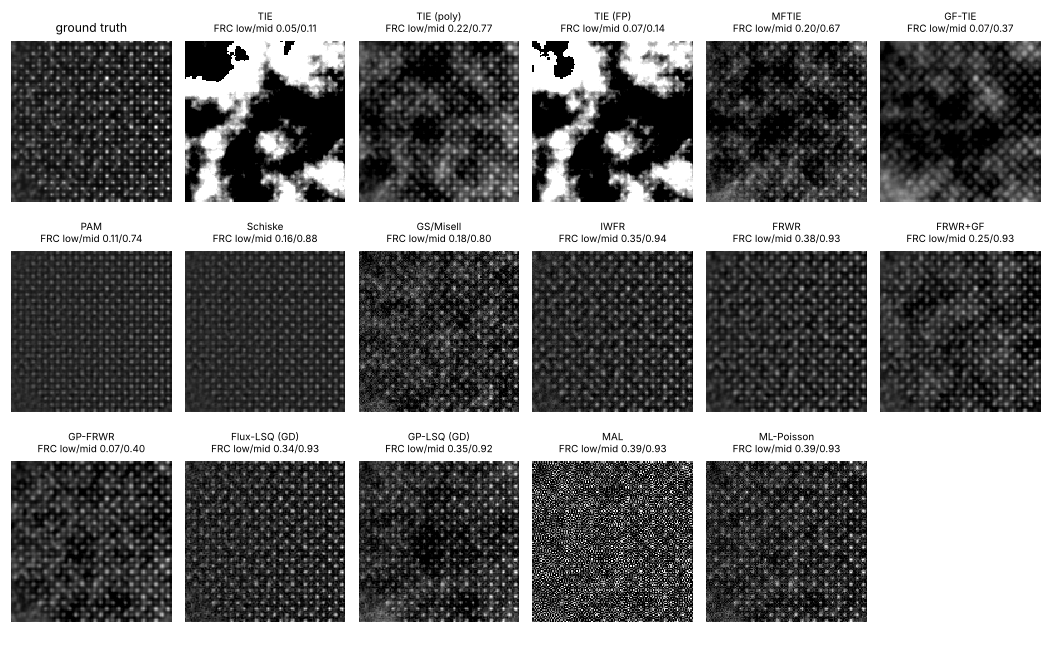

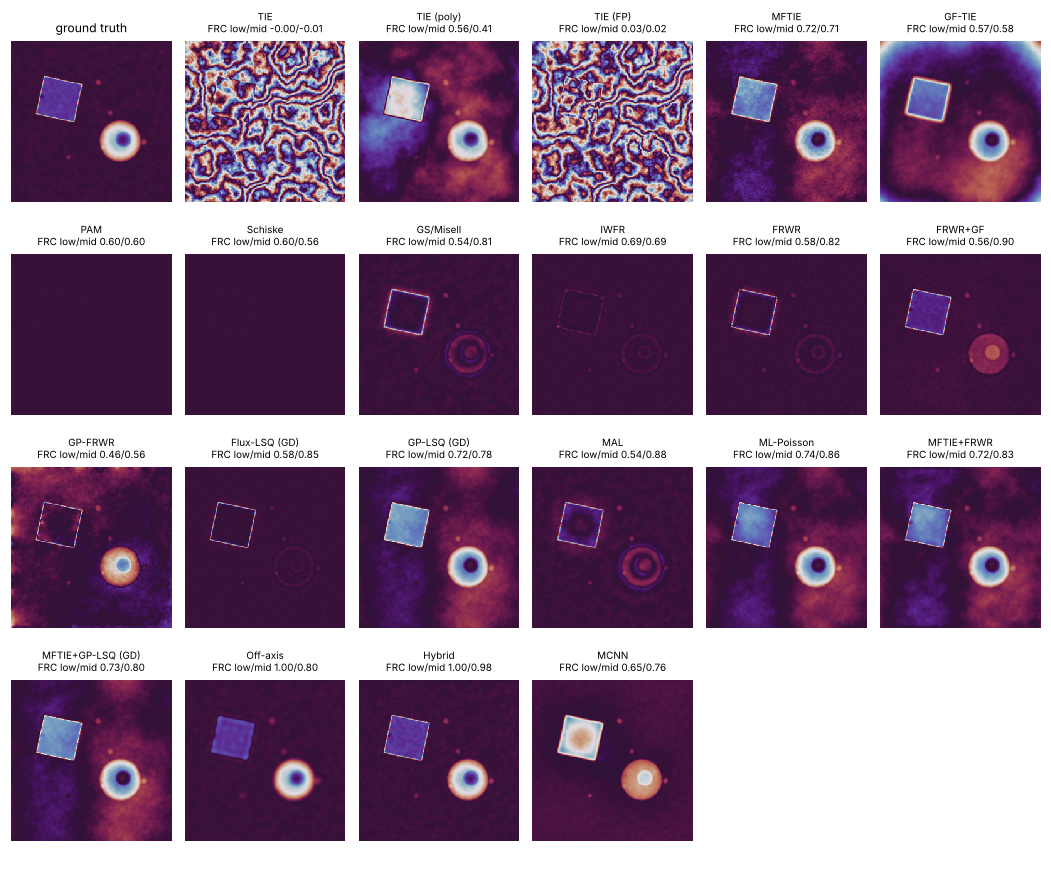

In [9]:
from scipy.ndimage import gaussian_filter
def show_recs(ds, crop=None, cmap="gray", fn=None, wrap=False, highpass_nm=None):
    res = ref[ds]; n = len(res) + 1
    def prep(ph):
        if highpass_nm:
            return ph - gaussian_filter(ph, highpass_nm / P[ds].pixel_size_nm, mode="wrap")
        return ph
    cols = 6; rows = int(np.ceil(n / cols))
    fig, ax = plt.subplots(rows, cols, figsize=(1.6 * cols, 2.0 * rows))
    ax = ax.ravel(); c = crop or slice(None)
    gt = GT[ds]
    ph = prep(np.angle(gt))
    vmin, vmax = (ph[c, c].min(), ph[c, c].max()) if not wrap else (-np.pi, np.pi)
    ax[0].imshow(ph[c, c], cmap=cmap, vmin=vmin, vmax=vmax); ax[0].set_title("ground truth")
    for k, (lab, (r, cc)) in enumerate(res.items()):
        w = align_global_phase(r.wave, gt)
        ax[k + 1].imshow(prep(np.angle(w))[c, c], cmap=cmap, vmin=vmin, vmax=vmax)
        ax[k + 1].set_title(f"{lab}\nFRC low/mid {cc['frc_low']:.2f}/{cc['frc_mid']:.2f}", fontsize=6.5)
    for a in ax: a.axis("off")
    fig.tight_layout()
    if fn: fig.savefig(os.path.join(FIG, fn))
    plt.show()

show_recs("hr", crop=slice(64, 192), fn="fig_recs_hr.pdf", highpass_nm=0.5)   # low frequencies (q < ~0.3/nm) removed for display
show_recs("mr", cmap="twilight", wrap=True, fn="fig_recs_mr.pdf")

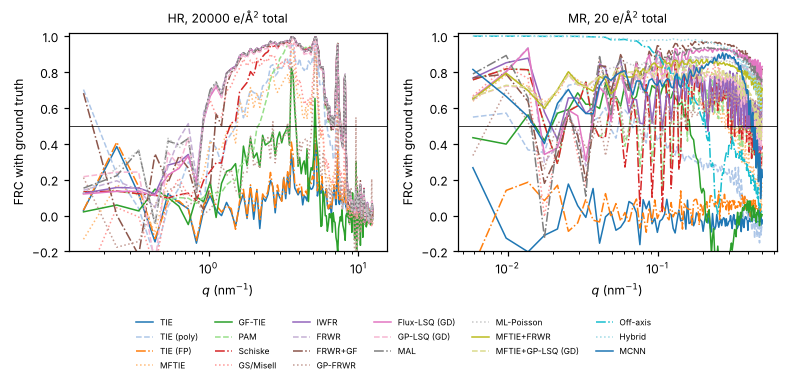

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(7.2, 3.4))
styles = ["-", "--", "-.", ":"]
COL = plt.cm.tab20(np.linspace(0, 1, 20))
MARK = "osd^v<>ph*XPDH8"
for a, ds in zip(ax, ("hr", "mr")):
    for k, (lab, (r, c)) in enumerate(ref[ds].items()):
        a.plot(c["q"][1:], c["frc"][1:], styles[k % 4], color=COL[k % 20], lw=1, label=lab)
    a.axhline(0.5, color="k", lw=0.5)
    a.set_xscale("log"); a.set_ylim(-0.2, 1.02)
    a.set_xlabel(r"$q$ (nm$^{-1}$)"); a.set_ylabel("FRC with ground truth")
    a.set_title(f"{ds.upper()}, {dose_ref[ds]:g} e/Å$^2$ total")
h, l = ax[1].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=6, fontsize=5.5, frameon=False)
fig.tight_layout(rect=(0, 0.16, 1, 1)); fig.savefig(os.path.join(FIG, "fig_frc_ref.pdf")); plt.show()

## 4  Dose dependence

The same noise-free series is scaled to different total doses and Poisson noise is added.
We report the band-averaged FRC with the ground truth (low: $q<0.1\,q_N$, mid: $0.1$–$0.4\,q_N$,
high: $0.4$–$1\,q_N$), the resolution defined as the highest frequency with FRC ≥ 0.5, and the
amplitude-weighted rms phase error.

In [11]:
RES = os.path.abspath(os.path.join("..", "results")); os.makedirs(RES, exist_ok=True)
DOSES = {"hr": [2e3, 2e4, 2e5] if FAST else [2e3, 6e3, 2e4, 6e4, 2e5, 2e6],
         "mr": [2, 20, 200] if FAST else [0.5, 2, 6, 20, 60, 200]}
rows = []
for ds in ("hr", "mr"):
    for dose in DOSES[ds]:
        cache = os.path.join(RES, f"cache_{ds}_{dose:g}.json")
        if os.path.exists(cache):
            rows += json.load(open(cache)); print(ds, dose, "cached"); continue
        res = ref[ds] if dose == dose_ref[ds] else run_all(ds, dose, seed=1000 + int(round(1000 * np.log10(dose))) % 100000, verbose=False)
        new = []
        for lab, (r, c) in res.items():
            new.append(dict(dataset=ds, dose=dose, method=lab, frc_low=c["frc_low"], frc_mid=c["frc_mid"],
                            frc_high=c["frc_high"], mean_frc=c["mean_frc"], d_res=c["d_res"],
                            rms_phase=c["rms_phase"], nrmse=c["nrmse"], runtime=r.runtime_s))
        json.dump(new, open(cache, "w")); rows += new
        print(ds, dose, "done")
df = pd.DataFrame(rows)
df.to_csv(os.path.join("..", "results", "dose_series.csv"), index=False)
df.head()

hr 2000.0 done


hr 6000.0 done
hr 20000.0 done


hr 60000.0 done


hr 200000.0 done


hr 2000000.0 done


mr 0.5 done


mr 2 done


mr 6 done
mr 20 done


mr 60 done


mr 200 done


,dataset,dose,method,frc_low,frc_mid,frc_high,mean_frc,d_res,rms_phase,nrmse,runtime
0,hr,2000.0,TIE,0.035988,-0.004644,-0.002693,0.000378,NaN,1.760921,21.032757,0.005953
1,hr,2000.0,TIE (poly),0.102440,0.236189,0.058595,0.115876,NaN,1.052814,17.347526,0.017365
2,hr,2000.0,TIE (FP),0.053080,-0.003884,-0.002746,0.002188,NaN,1.772181,21.040263,0.035872
3,hr,2000.0,MFTIE,0.133486,0.312069,0.062741,0.144028,0.19062,0.537095,10.743490,0.075519
4,hr,2000.0,GF-TIE,0.075504,0.132543,0.002524,0.048323,NaN,1.003151,17.092116,1.760341


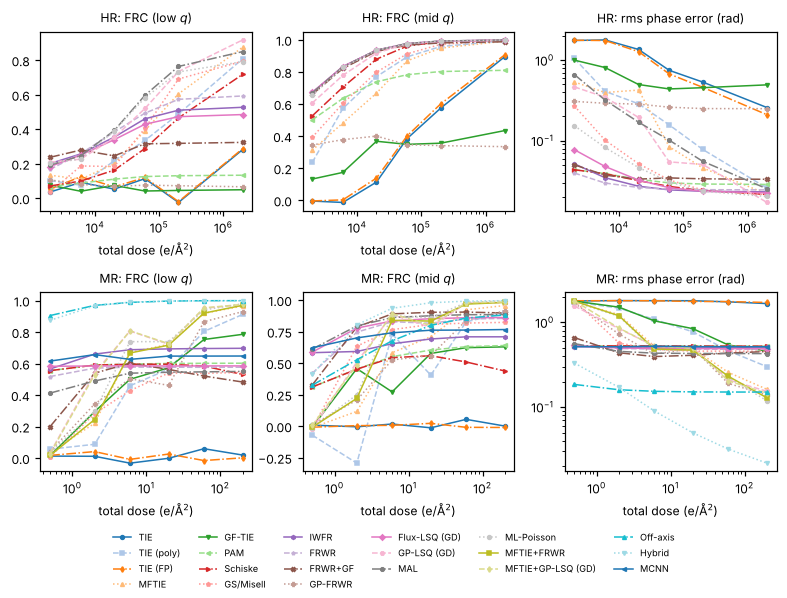

In [12]:
fig, ax = plt.subplots(2, 3, figsize=(7.2, 5.4))
metrics = [("frc_low", "FRC (low $q$)"), ("frc_mid", "FRC (mid $q$)"), ("rms_phase", "rms phase error (rad)")]
for i, ds in enumerate(("hr", "mr")):
    d = df[df.dataset == ds]
    for j, (m, lab) in enumerate(metrics):
        a = ax[i, j]
        for k, (meth, g) in enumerate(d.groupby("method", sort=False)):
            a.plot(g.dose, g[m], styles[k % 4], color=COL[k % 20], marker=MARK[k % len(MARK)], ms=2.5, lw=1, label=meth)
        a.set_xscale("log")
        if m == "rms_phase": a.set_yscale("log")
        a.set_title(f"{ds.upper()}: {lab}")
        if i == 1: a.set_xlabel("total dose (e/Å$^2$)")
for i in range(2):
    ax[i, 0].set_xlabel("total dose (e/Å$^2$)"); ax[i, 1].set_xlabel("total dose (e/Å$^2$)")
h, l = ax[1, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=6, fontsize=6, frameon=False)
fig.tight_layout(rect=(0, 0.1, 1, 1)); fig.savefig(os.path.join(FIG, "fig_dose.pdf")); plt.show()

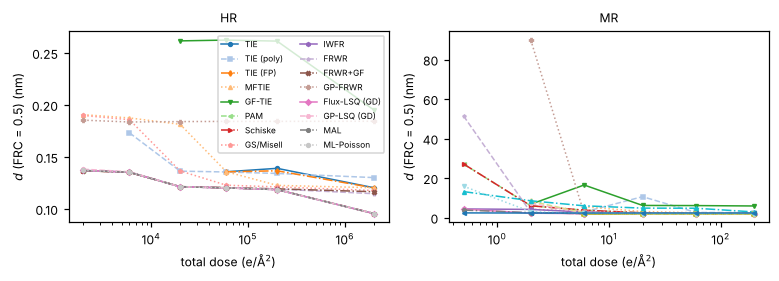

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.6))
for a, ds in zip(ax, ("hr", "mr")):
    d = df[df.dataset == ds]
    for k, (meth, g) in enumerate(d.groupby("method", sort=False)):
        a.plot(g.dose, g.d_res, styles[k % 4], color=COL[k % 20], marker=MARK[k % len(MARK)], ms=2.5, lw=1, label=meth)
    a.set_xscale("log"); a.set_xlabel("total dose (e/Å$^2$)"); a.set_ylabel("$d$ (FRC = 0.5) (nm)")
    a.set_title(ds.upper())
ax[0].legend(fontsize=5.5, ncol=2)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "fig_dose_resolution.pdf")); plt.show()

## 5  FRC without ground truth: half-data-set FRC

In experiments the ground truth is unknown. Following the cryo-EM practice (and the focal-series
quality assessment by Huang *et al.*, 2021), each recorded image can be split into two statistically
independent halves by binomial thinning of the electron counts. The two half-series are reconstructed
independently and their FRC is compared with the half-bit threshold. For an unbiased reconstruction
the half-set FRC is related to the FRC with the truth by $\mathrm{FRC}_\mathrm{truth}\approx\sqrt{2\,\mathrm{FRC}_\mathrm{half}/(1+\mathrm{FRC}_\mathrm{half})}$
(Rosenthal & Henderson 2003). Note that *systematic* errors common to both halves (wrong
parameters, model errors, the poorly transferred low frequencies) are **not** detected by the half-set FRC.

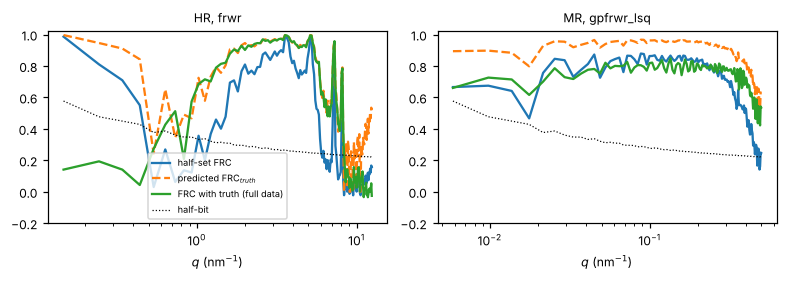

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.6))
half_rows = []
for a, ds, meth, opt in ((ax[0], "hr", "frwr", dict(n_iter=it["grad"])), (ax[1], "mr", "gpfrwr_lsq", dict(n_iter=it["grad"], init="mftie"))):
    I = noisy(I0[ds], P[ds], dose_ref[ds])
    h1, h2 = binomial_split(I, rng=1)
    r1 = ih.reconstruct(h1, P[ds], meth, **opt); r2 = ih.reconstruct(h2, P[ds], meth, **opt)
    q, fh, npts = frc(align_global_phase(r1.wave, r2.wave), r2.wave, P[ds].pixel_size_nm)
    rf = ih.reconstruct(I, P[ds], meth, **opt)
    ct = compare_to_truth(rf.wave, GT[ds], P[ds].pixel_size_nm)
    pred = np.sqrt(np.clip(2 * fh / (1 + fh), 0, 1))
    a.plot(q[1:], fh[1:], label="half-set FRC")
    a.plot(q[1:], pred[1:], "--", label="predicted FRC$_{truth}$")
    a.plot(q[1:], ct["frc"][1:], label="FRC with truth (full data)")
    a.plot(q[1:], half_bit_threshold(npts)[1:], "k:", lw=0.8, label="half-bit")
    a.set_xscale("log"); a.set_ylim(-0.2, 1.02); a.set_xlabel(r"$q$ (nm$^{-1}$)"); a.set_title(f"{ds.upper()}, {meth}")
ax[0].legend(fontsize=6)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "fig_halfset.pdf")); plt.show()

## 5b  Strain mapping by dark-field inline holography (DIH)

In DIH (Koch *et al.* 2010; Özdöl *et al.* 2010, 2012; Park *et al.* 2022) a focal series of dark-field images is recorded
with one Bragg reflection $\mathbf g$ aligned with the optic axis and selected by a small objective aperture. The phase of the
reconstructed diffracted wave is the geometric phase $\varphi_g=-2\pi\,\mathbf g\cdot\mathbf u$ (plus a mean-inner-potential term),
and the strain along $\mathbf g$ follows from its gradient, $\varepsilon_{gg}=-\hat{\mathbf g}\cdot\nabla\varphi_g/(2\pi|\mathbf g|)$,
which is computed directly from the complex wave (no unwrapping).
Test object: InGaN/GaN-like multi-quantum-well stack (0002 reflection, $|\mathbf g|=3.86$ nm$^{-1}$, 4 wells of 2.7 nm,
tetragonal strain up to ≈3 % with lateral composition fluctuations and strain relaxation towards the free surfaces,
0.1 rad MIP step); 200 kV, 0.25 nm pixels, 10 µm objective aperture (≈0.8 nm resolution), 13 images with defocus up to ±4 µm.
The strain is referenced to the GaN barriers and smoothed with a Gaussian of 1 pixel.

In [15]:
w_dih, eps_true, barrier, g_dih = sim.dih_object(256, 0.25)
p_dih = sim.dih_parameters(mtf={"type": "sinc"})
fn = os.path.join(DATA, "dih_noisefree.npy")
if os.path.exists(fn):
    I0_dih = np.load(fn)
else:
    I0_dih, _ = sim.simulate_focal_series(w_dih, p_dih, None, n_defocus=9, n_tilt=5)
    np.save(fn, I0_dih)
eps_ref, _ = strain.strain_1d(w_dih, g_dih, 0.25, sigma_px=1.0, ref_mask=barrier)   # band-limited reference
DIH_METHODS = [("TIE (poly)", "tie_poly", {}), ("MFTIE", "mftie", {}),
               ("FRWR", "frwr", dict(n_iter=it["grad"])), ("MFTIE+FRWR", "frwr", dict(n_iter=it["grad"], init="mftie")),
               ("FRWR+GF", "frwr_gf", dict(n_iter=it["grad"])), ("Flux-LSQ (GD)", "frwr_gd", dict(n_iter=it["grad"])),
               ("GP-LSQ (GD)", "gpfrwr_lsq", dict(n_iter=it["grad"])), ("MAL", "mal", dict(n_iter=it["lbfgs"]))]
DIH_DOSES = [30, 300] if FAST else [30, 100, 300, 1000, 3000]      # mean counts per pixel and image
dih_rows, dih_maps = [], {}
for dose in DIH_DOSES:
    I = np.random.default_rng(int(dose)).poisson(I0_dih / I0_dih.mean() * dose).astype(float)
    for lab, m, opt in DIH_METHODS:
        r = ih.reconstruct(I, p_dih, m, **opt)
        e, _ = strain.strain_1d(r.wave, g_dih, 0.25, sigma_px=1.0, ref_mask=barrier)
        err = float(np.sqrt(np.mean((e - eps_ref) ** 2)))
        c = compare_to_truth(r.wave, w_dih, 0.25)
        dih_rows.append(dict(dose=dose, method=lab, strain_rms_err=err, frc_low=c["frc_low"], frc_mid=c["frc_mid"],
                             runtime=r.runtime_s))
        if dose == 300:
            dih_maps[lab] = (e, r)
dih = pd.DataFrame(dih_rows); dih.to_csv(os.path.join("..", "results", "dih_strain.csv"), index=False)
dih.pivot_table(index="method", columns="dose", values="strain_rms_err", sort=False).mul(100).round(3)

dose,30,100,300,1000,3000
method,,,,,
TIE (poly),0.156,0.130,0.121,0.119,0.120
MFTIE,0.308,0.161,0.095,0.054,0.037
FRWR,0.364,0.333,0.338,0.335,0.324
MFTIE+FRWR,0.159,0.096,0.070,0.060,0.056
FRWR+GF,0.672,1.250,0.691,0.532,0.448
Flux-LSQ (GD),0.467,0.449,0.445,0.443,0.442
GP-LSQ (GD),0.147,0.081,0.047,0.027,0.017
MAL,0.353,0.236,0.198,0.176,0.172


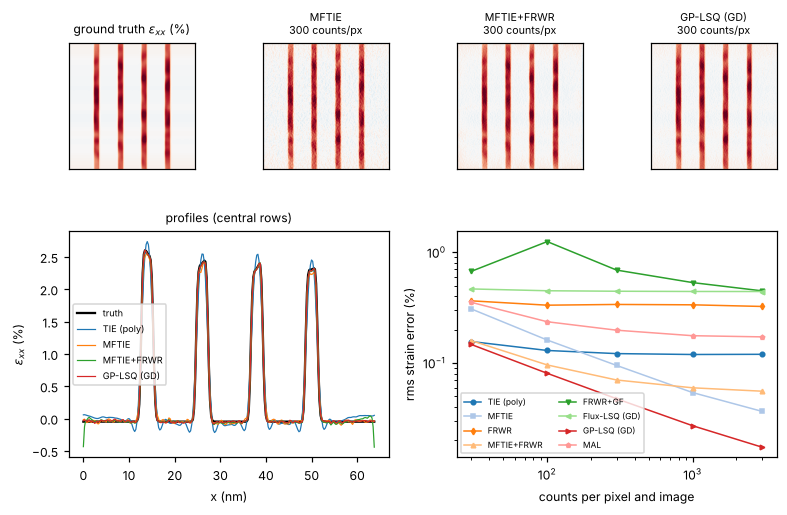

In [16]:
fig = plt.figure(figsize=(7.2, 5.0))
gs_ = fig.add_gridspec(2, 4, height_ratios=[1, 0.9])
show = ["TIE (poly)", "MFTIE", "MFTIE+FRWR", "GP-LSQ (GD)"]
vm = 100 * np.percentile(np.abs(eps_ref), 99.5)
ax0 = fig.add_subplot(gs_[0, 0]); ax0.imshow(100 * eps_ref, cmap="RdBu_r", vmin=-vm, vmax=vm); ax0.set_title("ground truth $\\varepsilon_{xx}$ (%)")
for k, lab in enumerate(show[1:]):
    a = fig.add_subplot(gs_[0, k + 1]); im = a.imshow(100 * dih_maps[lab][0], cmap="RdBu_r", vmin=-vm, vmax=vm)
    a.set_title(f"{lab}\n300 counts/px", fontsize=7)
for a in fig.axes: a.set_xticks([]); a.set_yticks([])
a = fig.add_subplot(gs_[1, :2])
x = np.arange(256) * 0.25; rows = slice(96, 160)
a.plot(x, 100 * eps_ref[rows].mean(0), "k", lw=1.5, label="truth")
for lab in show:
    a.plot(x, 100 * dih_maps[lab][0][rows].mean(0), lw=0.8, label=lab)
a.set_xlabel("x (nm)"); a.set_ylabel("$\\varepsilon_{xx}$ (%)"); a.legend(fontsize=6); a.set_title("profiles (central rows)")
a = fig.add_subplot(gs_[1, 2:])
for k, (lab, g_) in enumerate(dih.groupby("method", sort=False)):
    a.loglog(g_.dose, 100 * g_.strain_rms_err, marker=MARK[k], color=COL[k], lw=1, ms=3, label=lab)
a.set_xlabel("counts per pixel and image"); a.set_ylabel("rms strain error (%)"); a.legend(fontsize=5.5, ncol=2)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "fig_dih.pdf")); plt.show()

In [ ]:
# user metadata required by the NXem application definition (simulated data sets)
SIM_META = {
    "hr": {"sample": {"name": "SrTiO3-like [001] particle on amorphous carbon (simulated)", "atom_types": "Sr, Ti, O, C",
                      "preparation_date": "2026-01-01", "physical_form": "thin_film"}},
    "mr": {"sample": {"name": "MgO-like cube and metal-core carbon sphere on amorphous film (simulated)",
                      "atom_types": "Mg, O, C, Au", "preparation_date": "2026-01-01", "physical_form": "thin_film"}},
    "dih": {"sample": {"name": "InGaN/GaN multi-quantum-well stack, (0002) dark field (simulated)",
                       "atom_types": "In, Ga, N", "preparation_date": "2026-01-01", "physical_form": "foil"}},
}
for d in SIM_META.values():
    d["experiment"] = {"description": "simulated focal series (inlineholo.simulate)"}

In [17]:
fn = os.path.join(DATA, "dih_focal_series_sim.nxs")
I = np.random.default_rng(300).poisson(I0_dih / I0_dih.mean() * 300).astype(float)
ih.nxem.write_focal_series(fn, I, p_dih, ground_truth=w_dih, is_simulation=True, metadata=SIM_META["dih"],
                           description="simulated dark-field (0002) focal series of an InGaN/GaN MQW stack (DIH), 300 counts/px",
                           extra_metadata=dict(reflection_g_per_nm=list(g_dih), technique="dark-field inline holography"))
for lab in show:
    ih.nxem.write_reconstruction(fn, dih_maps[lab][1], p_dih, label=lab)
print(fn, os.path.getsize(fn) / 1e6, "MB")

../data/dih_focal_series_sim.nxs 12.429728 MB


## 6  NXem export / import

In [18]:
for ds in ("hr", "mr"):
    fn = os.path.join(DATA, f"{ds}_focal_series_sim.nxs")
    I = noisy(I0[ds], P[ds], dose_ref[ds])
    ih.nxem.write_focal_series(fn, I, P[ds], ground_truth=GT[ds], is_simulation=True, metadata=SIM_META[ds],
                               description=f"simulated {ds.upper()} focal series, total dose {dose_ref[ds]} e/A^2")
    for lab, (r, c) in ref[ds].items():
        ih.nxem.write_reconstruction(fn, r, P[ds], label=lab)
    stack, p2, gt2, recs = ih.nxem.read_focal_series(fn)
    assert np.allclose(stack, I) and np.allclose(p2.defoci_nm, P[ds].defoci_nm) and np.allclose(gt2, GT[ds])
    print(fn, "->", stack.shape, "images,", len(recs), "reconstructions;", os.path.getsize(fn) / 1e6, "MB")
    ok, problems, _ = ih.nxem.validate(fn)       # pynxtools (pip install pynxtools pynxtools-em)
    print("   NXem validation:", {True: "valid", False: "NOT valid", None: "skipped"}[ok], *problems[:5])

../data/hr_focal_series_sim.nxs -> (16, 256, 256) images, 16 reconstructions; 27.919672 MB


../data/mr_focal_series_sim.nxs -> (13, 256, 256) images, 21 reconstructions; 31.091352 MB


In [19]:
import h5py
with h5py.File(os.path.join(DATA, "hr_focal_series_sim.nxs")) as f:
    def show(name, obj):
        depth = name.count("/")
        skip = any(f"event{k}" in name.split("/") for k in range(2, 100)) or \
               any(f"image{k}" in name.split("/") for k in range(2, 100))
        if depth < 7 and not skip:
            cls = obj.attrs.get("NX_class", "") if isinstance(obj, h5py.Group) else ""
            print("  " * depth + name.split("/")[-1], f"[{cls}]" if cls else "")
    f.visititems(show)

entry1 [NXentry]
  definition 
  experiment_description 
  measurement [NXem_measurement]
    event1 [NXem_event_data]
      image1 [NXimage]
        image_2d [NXdata]
          axis_i 
          axis_j 
          real 
          title 
      instrument [NXem_instrument]
        ebeam_column [NXebeam_column]
          corrector_cs1 [NXcorrector_cs]
            tableau1 [NXprocess]
        optics [NXem_optical_system]
          defocus 
    instrument [NXem_instrument]
      ebeam_column [NXebeam_column]
        corrector_cs1 [NXcorrector_cs]
          tableau1 [NXprocess]
            c_1_2_a [NXaberration]
            c_1_2_b [NXaberration]
            c_2_1_a [NXaberration]
            c_3_0 [NXaberration]
        electron_source [NXsource]
          voltage 
      inline_holography [NXparameters]
        detector_mtf 
        focal_spread 
        global_defocus_offset 
        pixel_size 
      optics [NXem_optical_system]
        semi_convergence_angle 
  profiling [NXcs_profiling]

## 6b  FRWR: validation of the in-memory/GPU port against the FRWR3 C++ program

`method="frwr"` is a loop-by-loop port of C. T. Koch's FRWR3 program (2019 source code), configured with the
same keys as the frwr3 control file (YAML or `.conf`). It was validated by running the (patched, see the
manuscript) C++ program and the port on identical netCDF inputs and configurations that switch on one feature
at a time (scripts in `code/tests`, results in `results/frwr3_validation.json`; the C++ binary itself is not part
of this package). Shown are the R-value traces of all loops and the maximum relative deviation of the traces.

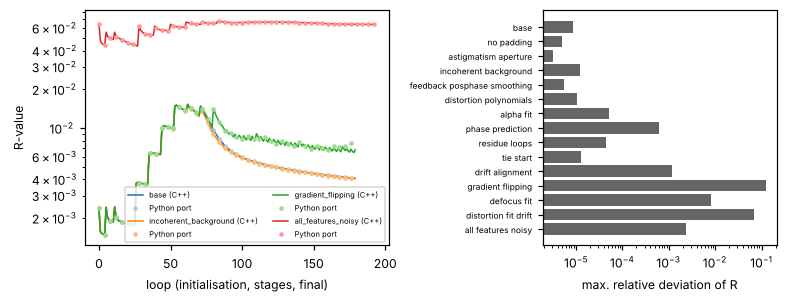

,test,loops,max_rel_dev_R,R_cpp,R_py,FRC_cpp_py_low,FRC_cpp_py_high,t_cpp,t_py
0,base,180,0.00001,0.00408,0.00408,1.0000,1.0000,12.00673,13.09274
1,no_padding,180,0.00001,0.00403,0.00403,1.0000,1.0000,10.51413,8.30104
2,astigmatism_aperture,171,0.00000,0.01516,0.01516,1.0000,1.0000,18.71914,11.23977
3,incoherent_background,180,0.00001,0.00405,0.00405,1.0000,1.0000,13.47607,12.56728
4,feedback_posphase_smoothing,180,0.00001,0.01486,0.01486,1.0000,1.0000,12.32044,12.51600
5,distortion_polynomials,171,0.00001,0.02225,0.02225,1.0000,1.0000,11.30882,11.51983
6,alpha_fit,180,0.00005,0.00618,0.00618,1.0000,1.0000,14.59797,13.43649
7,phase_prediction,201,0.00061,0.06322,0.06320,1.0000,1.0000,22.55704,27.18757
8,residue_loops,116,0.00004,0.00778,0.00778,0.9960,0.9999,7.24600,7.59724
9,tie_start,100,0.00001,0.00736,0.00736,1.0000,1.0000,5.63631,4.45177


In [20]:
val = json.load(open(os.path.join("..", "results", "frwr3_validation.json")))
rows = []
for name, v in val.items():
    rows.append(dict(test=name, loops=v["n_cpp"], max_rel_dev_R=v["max_rel"], R_cpp=v["R_cpp"], R_py=v["R_py"],
                     FRC_cpp_py_low=v.get("frc_py_cpp", [np.nan] * 3)[0], FRC_cpp_py_high=v.get("frc_py_cpp", [np.nan] * 3)[2],
                     t_cpp=v["t_cpp"], t_py=v["t_py"]))
V = pd.DataFrame(rows); V.to_csv(os.path.join("..", "results", "frwr3_validation.csv"), index=False)
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.8), gridspec_kw=dict(width_ratios=[1.3, 1]))
for k, name in enumerate(["base", "incoherent_background", "gradient_flipping", "all_features_noisy"]):
    v = val[name]; x = np.arange(len(v["trace_cpp"]))
    ax[0].plot(x, v["trace_cpp"], "-", color=COL[2 * k], lw=1, label=f"{name} (C++)")
    ax[0].plot(x[::4], np.array(v["trace_py"])[::4], "o", ms=2, color=COL[2 * k + 1], label="Python port")
ax[0].set_yscale("log"); ax[0].set_xlabel("loop (initialisation, stages, final)"); ax[0].set_ylabel("R-value")
ax[0].legend(fontsize=5, ncol=2)
ax[1].barh(np.arange(len(V)), V.max_rel_dev_R, color="0.4"); ax[1].set_xscale("log")
ax[1].set_yticks(np.arange(len(V))); ax[1].set_yticklabels(V.test.str.replace("_", " "), fontsize=5.5)
ax[1].set_xlabel("max. relative deviation of R"); ax[1].invert_yaxis()
fig.tight_layout(); fig.savefig(os.path.join(FIG, "fig_frwr3_validation.pdf")); plt.show()
V.round(5)

In [21]:
# backends: the same FRWR3 reconstruction on NumPy (float64/float32) and PyTorch (CPU here; CUDA/MPS if present)
from inlineholo.backend import available_backends
print("available back ends:", available_backends())
Ib = noisy(I0["mr"], P["mr"], dose_ref["mr"])
bt = []
for be, prec in (("numpy", "float64"), ("numpy", "float32"), ("torch", "float32")):
    try:
        t0 = time.time(); rb = ih.reconstruct(Ib, P["mr"], "frwr", n_iter=it["grad"], backend=be, precision=prec)
        cb_ = compare_to_truth(rb.wave, GT["mr"], P["mr"].pixel_size_nm)
        bt.append(dict(backend=rb.extra["frwr3"].backend, precision=prec, runtime_s=time.time() - t0, FRC_mid=cb_["frc_mid"]))
    except Exception as e:
        print(be, "not available:", e)
pd.DataFrame(bt).round(3)

available back ends: ['numpy', 'torch(cpu)']


,backend,precision,runtime_s,FRC_mid
0,numpy/cpu,float64,11.737,0.817
1,numpy/cpu,float32,7.946,0.817
2,torch/cpu,float32,4.993,0.817


## 6c  Diffuse energy flow: Fokker–Planck generalization of the TIE

Paganin & Morgan (2019, 2026) and Paganin, Pelliccia & Morgan (2023) add a diffusive term to the TIE,
$I(\Delta)=I_0-\frac{\Delta}{k}\nabla\cdot[(1-F)I_0\nabla\varphi]+\Delta^2\nabla^2[D I_0]$, with the diffusion field
$D=(\theta_0^2+F\theta_s^2)/2$ (source size $\theta_0$, small-angle scattering by unresolved micro-structure $\theta_s$, scattered fraction $F$).
We simulate a one-sided focal series (0, 200, 400, 600 nm) of a smooth phase object with a localized diffusion field, and compare
(i) the first-order TIE from the two nearest planes, (ii) the Fokker–Planck-consistent three-plane TIE (`tie_fp`), and (iii) the
diffusion field retrieved from the residuals of the coherent model (`fokker_planck.diffusion_field`).

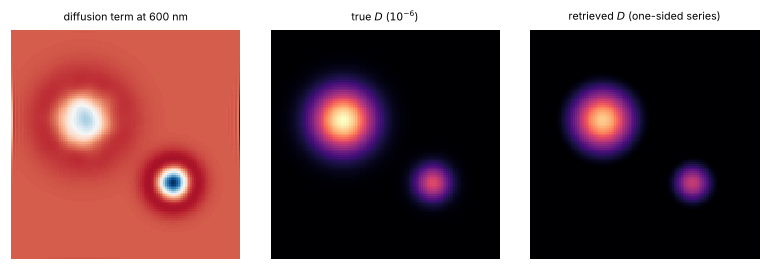

,series,method,rms_phase
0,symmetric,TIE (first order),0.1291
1,symmetric,"TIE (FP, 3 planes)",0.1291
2,symmetric,"TIE (FP), no diffusion",0.1291
3,symmetric,diffusion field: corr(D),0.9962
4,one-sided,TIE (first order),0.1676
5,one-sided,"TIE (FP, 3 planes)",0.1291
6,one-sided,"TIE (FP), no diffusion",0.1291
7,one-sided,diffusion field: corr(D),0.9973


In [22]:
from inlineholo import fokker_planck as fpk
from scipy.ndimage import gaussian_filter as gf_
rng_ = np.random.default_rng(0); nfp, pxfp = 128, 1.0
phfp = gf_(rng_.standard_normal((nfp, nfp)), 6, mode="wrap"); phfp /= phfp.std()
wfp = (1 - 0.1 * gf_(rng_.standard_normal((nfp, nfp)), 5, mode="wrap")) * np.exp(1j * phfp)
yy, xx = np.mgrid[0:nfp, 0:nfp]
Dfp = 1e-6 * (np.exp(-((xx - 40) ** 2 + (yy - 50) ** 2) / (2 * 12 ** 2)) + 0.6 * np.exp(-((xx - 90) ** 2 + (yy - 85) ** 2) / (2 * 7 ** 2)))
gfp = FourierGrid((nfp, nfp), pxfp)
lapDI = np.real(np.fft.ifft2(-4 * np.pi ** 2 * gfp.q2 * np.fft.fft2(Dfp * np.abs(wfp) ** 2)))
fp_rows = []
for zs, lab in (([-400., -200., 0., 200., 400.], "symmetric"), ([0., 200., 400., 600.], "one-sided")):
    pfp = ih.ImagingParameters(voltage_V=300e3, pixel_size_nm=pxfp, defoci_nm=np.array(zs))
    Ic = ih.ForwardModel(pfp, (nfp, nfp), "coherent", use_mtf=False).forward(wfp)
    Ifp = Ic + np.array(zs)[:, None, None] ** 2 * lapDI
    for name, rec in (("TIE (first order)", ih.reconstruct(Ifp, pfp, "tie_full", normalize=False)),
                      ("TIE (FP, 3 planes)", fpk.tie_fp(Ifp, pfp)),
                      ("TIE (FP), no diffusion", fpk.tie_fp(Ic, pfp))):
        fp_rows.append(dict(series=lab, method=name, rms_phase=compare_to_truth(rec.wave, wfp, pxfp)["rms_phase"]))
    dres = fpk.diffusion_field(Ifp + 0.02, pfp, wfp, model="coherent", background=True)
    fp_rows.append(dict(series=lab, method="diffusion field: corr(D)", rms_phase=np.corrcoef(dres["D"].ravel(), Dfp.ravel())[0, 1]))
fig, ax = plt.subplots(1, 3, figsize=(7.2, 2.4))
ax[0].imshow(Ifp[3] - Ic[3], cmap="RdBu_r"); ax[0].set_title("diffusion term at 600 nm", fontsize=7)
ax[1].imshow(Dfp * 1e6, cmap="magma"); ax[1].set_title(r"true $D$ ($10^{-6}$)", fontsize=7)
ax[2].imshow(dres["D"] * 1e6, cmap="magma", vmin=0, vmax=Dfp.max() * 1e6); ax[2].set_title(r"retrieved $D$ (one-sided series)", fontsize=7)
for a in ax: a.axis("off")
fig.tight_layout(); fig.savefig(os.path.join(FIG, "fig_fp.pdf")); plt.show()
pd.DataFrame(fp_rows).round(4)

## 7  Summary table (reference dose) for the manuscript

In [23]:
summ = []
for ds in ("hr", "mr"):
    for lab, (r, c) in ref[ds].items():
        summ.append(dict(dataset=ds.upper(), method=lab, FRC_low=c["frc_low"], FRC_mid=c["frc_mid"], FRC_high=c["frc_high"],
                         d_nm=c["d_res"], rms_phase=c["rms_phase"], runtime_s=r.runtime_s))
S = pd.DataFrame(summ)
S.to_csv(os.path.join("..", "results", "summary_reference_dose.csv"), index=False)
with open(os.path.join(os.path.dirname(FIG), "table_results.tex"), "w") as fh:
    fh.write("% generated by notebooks/01_method_comparison.ipynb\n")
    for ds in ("HR", "MR"):
        fh.write("\\midrule\n\\multicolumn{7}{l}{\\textit{%s}}\\\\\n" % ("High resolution" if ds == "HR" else "Medium resolution"))
        for _, r in S[S.dataset == ds].iterrows():
            dtxt = "---" if not np.isfinite(r.d_nm) else f"{r.d_nm:.3g}"
            fh.write(f"{r.method} & {r.FRC_low:.2f} & {r.FRC_mid:.2f} & {r.FRC_high:.2f} & {dtxt} & {r.rms_phase:.3f} & {r.runtime_s:.1f}\\\\\n")
S.round(3)

,dataset,method,FRC_low,FRC_mid,FRC_high,d_nm,rms_phase,runtime_s
0,HR,TIE,0.053,0.114,0.058,NaN,1.361,0.008
1,HR,TIE (poly),0.218,0.770,0.204,0.136,0.287,0.014
2,HR,TIE (FP),0.066,0.138,0.071,NaN,1.279,0.033
3,HR,MFTIE,0.200,0.668,0.152,0.181,0.426,0.094
4,HR,GF-TIE,0.074,0.368,0.009,0.262,0.499,1.678
5,HR,PAM,0.111,0.738,0.333,0.121,0.033,0.310
6,HR,Schiske,0.163,0.879,0.334,0.121,0.032,0.301
7,HR,GS/Misell,0.184,0.798,0.182,0.137,0.052,3.915
8,HR,IWFR,0.354,0.935,0.336,0.121,0.027,3.540
9,HR,FRWR,0.385,0.933,0.332,0.121,0.026,15.399
